**Checkpoint de 100 posições:** esta análise usa runs/hardpos/checkpoints/gpt_model_HardPos_.pt. Para o modelo de 10 posições, abra HardPos_saltos_ps_contexto10.ipynb.

# Saltos sintéticos entre centros de PS

Para cada PS, calculamos o centro médio (x,y) das posições da trajetória que receberam esse código. A distância entre centros de dois PS consecutivos define um deslocamento aproximado. Dividimos por um intervalo de referência fixo de 0,15 s para obter uma pseudovelocidade. Esta métrica não substitui a velocidade real do dataset: os intervalos reais entre registros variam.

Em cada contexto real de 99 tokens, mantemos os 98 primeiros PS e substituímos **somente o último** por PS em distâncias controladas do penúltimo: próximo, intermediário, grande, salto extremo e o PS mais distante disponível. Comparamos com o último PS real. A rede nunca recebe coordenadas, tempo nem velocidade; recebe apenas os IDs de PS. A probabilidade atribuída ao último PS é lida na penúltima posição, antes de o candidato ser visto. As ativações são lidas na última posição, depois de o candidato ser incorporado.

Chamamos de salto fora do envelope observado aquele cuja pseudovelocidade supera o maior valor da série real de transições entre centros. Isso indica ausência na trajetória amostrada sob esse intervalo de referência, sem estabelecer uma impossibilidade física universal.

In [1]:
%matplotlib inline
from pathlib import Path
import json, math, pickle
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from scipy.stats import spearmanr
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt
from IPython.display import display

root=Path('.')
df=pd.read_parquet(root/'runs/datasets/hardpos/bert_trainset_squared_25.gzip')
with (root/'runs/datasets/hardpos/ps_to_psid.pkl').open('rb') as f: mapping=pickle.load(f)
ids=df.position_state.map(mapping).to_numpy()
assert np.isfinite(ids).all()
ids=ids.astype(np.int64)
xy=np.stack(df.pos.to_numpy()).astype(float)
times=df.t.to_numpy(float)
dt=np.diff(times)
centers=pd.DataFrame({'ps_id':ids,'x':xy[:,0],'y':xy[:,1]}).groupby('ps_id',as_index=False)[['x','y']].mean()
centers.to_parquet(root/'runs/hardpos/analysis/HardPos_centros_ps.parquet',index=False)
center_array=np.full((ids.max()+1,2),np.nan)
center_array[centers.ps_id.to_numpy(int)]=centers[['x','y']].to_numpy(float)
real_distance=np.linalg.norm(center_array[ids[1:]]-center_array[ids[:-1]],axis=1)
real_proxy=real_distance/dt
reference_dt=float(np.median(dt))
max_real_distance=float(real_distance.max())
max_real_proxy=float(real_proxy.max())
print('PS com centro:',len(centers),'| intervalo de referência:',round(reference_dt,3),'s')
print('Distância real por transição: mediana',round(np.median(real_distance),3),'máximo',round(max_real_distance,3))
print('Distância/tempo real entre centros: máximo',round(max_real_proxy,3))
from project_support.csv_runs import notebook_csv_path


PS com centro: 947 | intervalo de referência: 0.15 s
Distância real por transição: mediana 0.032 máximo 0.129
Distância/tempo real entre centros: máximo 2.58


In [2]:
window=99
split_index=int(.8*len(ids))
rng=np.random.default_rng(43)
valid_t=np.arange(window-1,len(ids))
# Intervalos próximos da mediana para tornar a comparação entre transições mais direta.
eligible=valid_t[(dt[valid_t-1]>=.1)&(dt[valid_t-1]<=.2)]
train_candidates=eligible[eligible<split_index]
test_candidates=eligible[eligible>=split_index+window-1]
n_per_split=256
assert len(train_candidates)>=n_per_split and len(test_candidates)>=n_per_split
train_t=np.sort(rng.choice(train_candidates,n_per_split,replace=False))
test_t=np.sort(rng.choice(test_candidates,n_per_split,replace=False))
anchors=np.r_[train_t,test_t]
splits=np.array(['treino']*n_per_split+['teste']*n_per_split)
center_ids=centers.ps_id.to_numpy(int)
center_xy=centers[['x','y']].to_numpy(float)
category_targets=[('perto',.03,.01),('medio',.08,.01),('grande',.20,.015),('fora_envelope',.55,.025)]
records=[]; sequences=[]
for anchor_id,(t,split) in enumerate(zip(anchors,splits)):
    previous=int(ids[t-1]); actual=int(ids[t])
    distances=np.linalg.norm(center_xy-center_array[previous],axis=1)
    prefix=ids[t-window+1:t].copy()  # 98 tokens; ainda não contém o último
    used={previous}
    options=[('real',actual,float(np.linalg.norm(center_array[actual]-center_array[previous])))]
    used.add(actual)
    for category,target,tolerance in category_targets:
        available=np.flatnonzero((np.abs(distances-target)<=tolerance)&(~np.isin(center_ids,list(used))))
        if len(available)==0:
            available=np.argsort(np.abs(distances-target))
            available=np.array([j for j in available if center_ids[j] not in used][:12])
        choice=int(rng.choice(available))
        candidate=int(center_ids[choice]); used.add(candidate)
        options.append((category,candidate,float(distances[choice])))
    farthest=int(np.argmax(np.where(np.isin(center_ids,list(used)),-1,distances)))
    candidate=int(center_ids[farthest])
    options.append(('mais_distante',candidate,float(distances[farthest])))
    for category,candidate,distance in options:
        sequences.append(np.r_[prefix,candidate])
        records.append((anchor_id,split,int(t),previous,actual,candidate,category,distance,
                        distance/reference_dt,float(dt[t-1])))
inputs=np.stack(sequences).astype(np.int64)
meta=pd.DataFrame(records,columns=['anchor_id','split','t_index','previous_ps_id','actual_ps_id',
                                   'candidate_ps_id','category','centroid_distance','pseudo_speed','real_dt'])
assert inputs.shape==(n_per_split*2*6,window)
assert np.all(inputs[:,-2]==meta.previous_ps_id.to_numpy())
assert np.all(inputs[:,-1]==meta.candidate_ps_id.to_numpy())
assert (test_t-window+1>=split_index).all()
assert (meta.loc[meta.category=='fora_envelope','pseudo_speed']>max_real_proxy).all()
summary=meta.groupby(['split','category'])[['centroid_distance','pseudo_speed']].agg(['median','min','max']).round(3)
display(summary)
print('Janelas:',len(anchors),'| variantes:',len(meta))

centroid_distance               pseudo_speed         \
                                median    min    max       median    min   
split  category                                                            
teste  fora_envelope             0.549  0.525  0.575        3.662  3.501   
       grande                    0.200  0.185  0.215        1.332  1.234   
       mais_distante             0.933  0.645  1.238        6.222  4.300   
       medio                     0.080  0.056  0.090        0.533  0.376   
       perto                     0.032  0.020  0.069        0.215  0.135   
       real                      0.028  0.006  0.082        0.186  0.041   
treino fora_envelope             0.552  0.525  0.575        3.681  3.500   
       grande                    0.200  0.185  0.215        1.332  1.235   
       mais_distante             0.951  0.670  1.222        6.339  4.466   
       medio                     0.081  0.070  0.090        0.539  0.467   
       perto                     0.033  0.016  0.116        0.221  0.106   
       real                      0.028  0.006  0.087        0.188  0.039   

                             
                        max  
split  category              
teste  fora_envelope  3.832  
       grande         1.433  
       mais_distante  8.252  
       medio          0.599  
       perto          0.460  
       real           0.544  
treino fora_envelope  3.833  
       grande         1.433  
       mais_distante  8.150  
       medio          0.600  
       perto          0.772  
       real           0.578

Janelas: 512 | variantes: 3072


In [3]:
training_nb=json.loads((root/'navitran_vizz_reboot_gpt_squared_25_span.ipynb').read_text(encoding='utf-8'))
for cell_no in (21,23): exec(''.join(training_nb['cells'][cell_no]['source']),globals())
pad_id=int(ids.max())+1
model=TrajectoryBERT_HardPos(pad_id+1,embed_size=16,num_layers=1,num_heads=1,
                             hidden_dim=32,dropout=.2,pad_token_id=pad_id,max_len=100,causal=True)
model.load_state_dict(torch.load(root/'runs/hardpos/checkpoints/gpt_model_HardPos_.pt',map_location='cpu',weights_only=True))
model.eval()
torch.set_num_threads(min(4,torch.get_num_threads()))
layer=model.encoder.layers[0]

@torch.inference_mode()
def extract(batch):
    emb=model.embedding(batch)
    pos=model.position_embedding(emb)
    q,k,v=F.linear(pos,layer.self_attn.in_proj_weight,layer.self_attn.in_proj_bias).chunk(3,-1)
    mask=model._causal_mask(batch.shape[1],batch.device)
    attn,_=layer.self_attn(pos,pos,pos,attn_mask=mask,need_weights=False)
    residual1=pos+layer.dropout1(attn)
    norm1=layer.norm1(residual1)
    ff1=layer.linear1(norm1)
    ff_act=layer.activation(ff1)
    ff2=layer.linear2(layer.dropout(ff_act))
    norm2=layer.norm2(norm1+layer.dropout2(ff2))
    reps={'token_embedding':emb,'attention_output':attn,
          'ff_activation':ff_act,'encoder_output':norm2}
    # Com máscara causal, o logit na penúltima posição não vê o candidato final.
    logits=model.fc_out(norm2[:, -2, :])
    p=torch.softmax(logits,dim=-1).gather(1,batch[:,-1:].long()).squeeze(1)
    return {name:a[:,-1].numpy() for name,a in reps.items()},p.numpy(),norm2

blocks={}; probs=[]
for start in range(0,len(inputs),32):
    batch=torch.from_numpy(inputs[start:start+32])
    reps,p,encoder=extract(batch)
    if start==0:
        with torch.inference_mode():
            torch.testing.assert_close(model.fc_out(encoder[:,-1]),model(batch)[:,-1],atol=1e-5,rtol=1e-5)
            direct_p=torch.softmax(model(batch)[:,-2],dim=-1).gather(1,batch[:,-1:]).squeeze(1)
            torch.testing.assert_close(torch.from_numpy(p),direct_p,atol=1e-6,rtol=1e-6)
    probs.append(p)
    for name,a in reps.items(): blocks.setdefault(name,[]).append(a)
features={}
for name,chunks in blocks.items():
    values=np.concatenate(chunks)
    for j in range(values.shape[1]): features[f'{name}__d{j:02d}']=values[:,j]
results=pd.concat([meta,pd.DataFrame(features)],axis=1)
results['p_candidate_given_prefix']=np.concatenate(probs)
results['surprisal_nats']=-np.log(results.p_candidate_given_prefix.clip(lower=1e-30))
results.to_parquet(root/'runs/hardpos/analysis/HardPos_saltos_ps_ativacoes.parquet',index=False)
print('Dimensões:',len(features),'| linhas:',len(results))

/home/mgteus/workspace/navitrans/.nav/lib/python3.10/site-packages/torch/nn/modules/transformer.py:307: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.num_heads is odd
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


Dimensões: 80 | linhas: 3072


## Distância, plausibilidade e surpresa do modelo

As categorias com distância 0,20 e 0,55 já ultrapassam o maior deslocamento entre centros visto em uma transição real nesta trajetória. A categoria 0,55 também supera, com o intervalo de referência, o maior deslocamento/tempo real observado. O gráfico de probabilidade indica se o modelo atribui pouca chance ao PS candidato **antes** de recebê-lo.

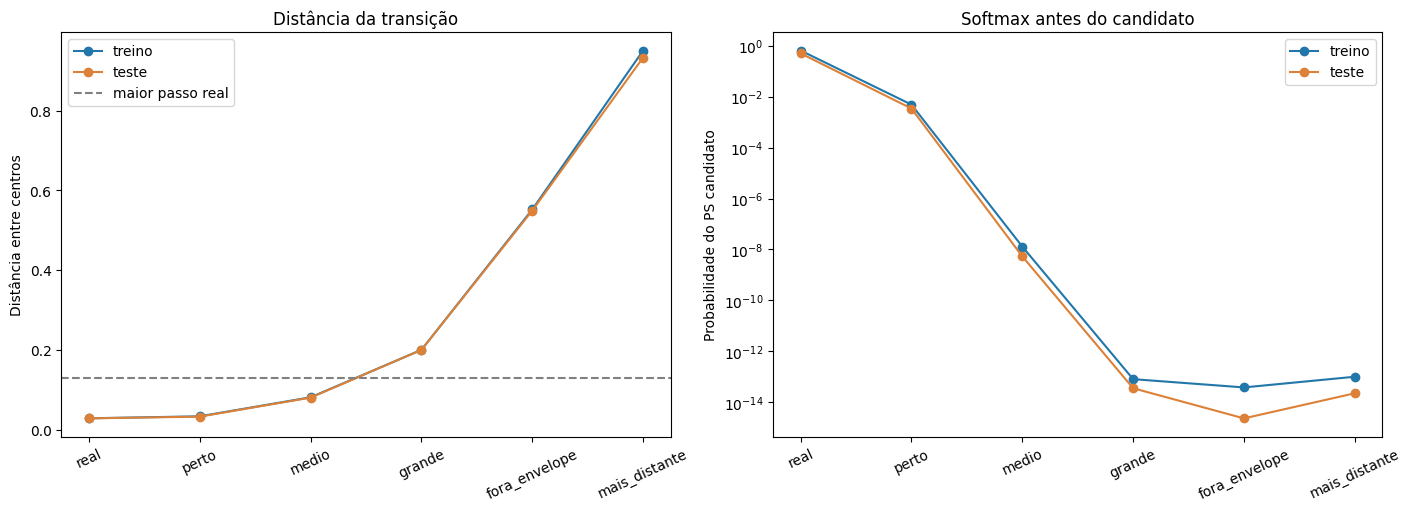

centroid_distance  pseudo_speed  \
split  category                                         
teste  fora_envelope            0.54934       3.66227   
       grande                   0.19987       1.33243   
       mais_distante            0.93325       6.22166   
       medio                    0.08000       0.53332   
       perto                    0.03232       0.21548   
       real                     0.02790       0.18603   
treino fora_envelope            0.55211       3.68076   
       grande                   0.19986       1.33240   
       mais_distante            0.95087       6.33914   
       medio                    0.08085       0.53899   
       perto                    0.03311       0.22072   
       real                     0.02817       0.18777   

                      p_candidate_given_prefix  
split  category                                 
teste  fora_envelope                   0.00000  
       grande                          0.00000  
       mais_distante                   0.00000  
       medio                           0.00000  
       perto                           0.00342  
       real                            0.50025  
treino fora_envelope                   0.00000  
       grande                          0.00000  
       mais_distante                   0.00000  
       medio                           0.00000  
       perto                           0.00486  
       real                            0.64616

In [4]:
order=['real','perto','medio','grande','fora_envelope','mais_distante']
fig,axes=plt.subplots(1,2,figsize=(14,5),constrained_layout=True)
for name,color in [('treino','#2277aa'),('teste','#dc8137')]:
    part=results[results.split==name]
    med=part.groupby('category').median(numeric_only=True).reindex(order)
    axes[0].plot(range(len(order)),med.centroid_distance,marker='o',label=name,color=color)
    axes[1].plot(range(len(order)),med.p_candidate_given_prefix,marker='o',label=name,color=color)
axes[0].axhline(max_real_distance,color='gray',ls='--',label='maior passo real')
axes[0].set(ylabel='Distância entre centros',title='Distância da transição')
axes[1].set_yscale('log')
axes[1].set(ylabel='Probabilidade do PS candidato',title='Softmax antes do candidato')
for ax in axes:
    ax.set_xticks(range(len(order)),order,rotation=25)
    ax.legend()
(root/'imgs').mkdir(exist_ok=True)
fig.savefig(root/'imgs/hardpos_saltos_distancia_softmax.png',dpi=150,bbox_inches='tight')
display(fig)
plt.close(fig)
display(results.groupby(['split','category'])[['centroid_distance','pseudo_speed','p_candidate_given_prefix']].median().round(5))

## Resposta das representações ao salto

Subtraímos, para cada contexto, a ativação da variante real. A norma da diferença mostra quanto a representação muda quando apenas o último PS é trocado. Uma mudança grande pode refletir o novo lugar, a raridade do PS ou o salto; por si só não demonstra codificação de velocidade. Calculamos também a correlação entre distância e cada dimensão dentro de cada contexto sintético, selecionando unidades pelo treino e exibindo a mesma unidade no teste.

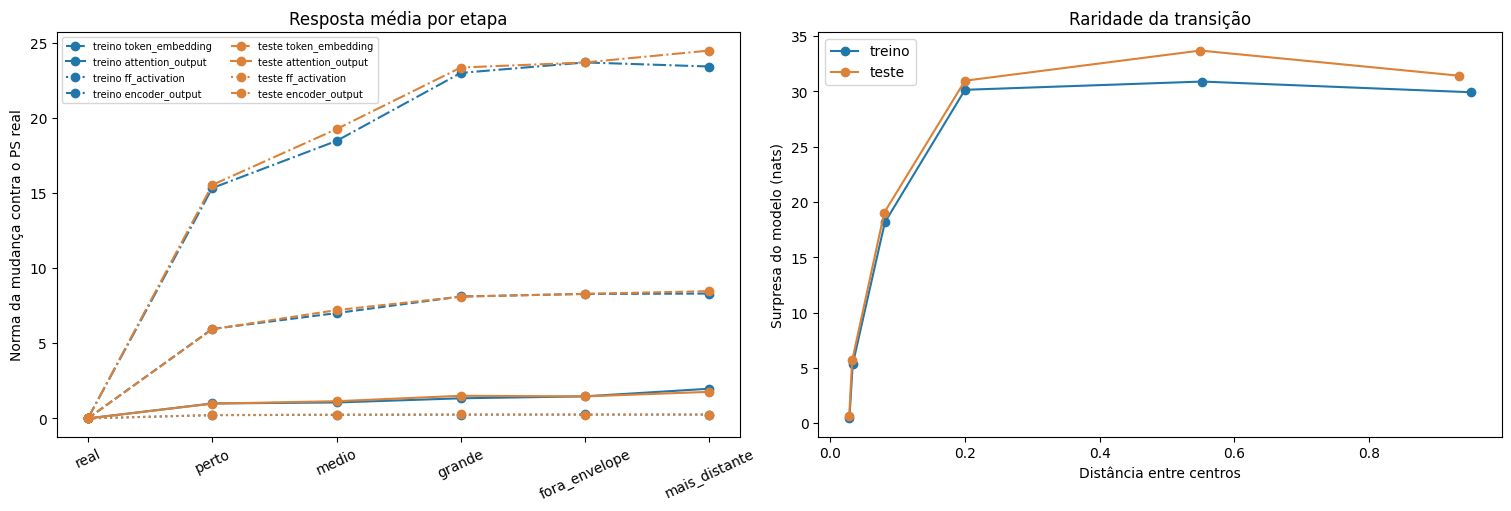

split,teste,treino
feature,,
attention_output__d08,-0.035,-0.137
encoder_output__d00,0.256,0.301
ff_activation__d06,0.511,0.511
token_embedding__d00,0.239,0.269


In [5]:
feature_cols=list(features)
for stage in blocks:
    cols=[c for c in feature_cols if c.startswith(stage+'__')]
    values=results[cols].to_numpy(float).reshape(len(anchors),6,len(cols))
    delta=np.linalg.norm(values-values[:,0:1,:],axis=2)
    results[stage+'_delta_from_real']=delta.reshape(-1)
fig,axes=plt.subplots(1,2,figsize=(15,5),constrained_layout=True)
for name,color in [('treino','#2277aa'),('teste','#dc8137')]:
    part=results[results.split==name]
    grouped=part.groupby('category').median(numeric_only=True).reindex(order)
    for stage,ls in [('token_embedding','--'),('attention_output','-'),('ff_activation',':'),('encoder_output','-.')]:
        axes[0].plot(range(len(order)),grouped[stage+'_delta_from_real'],ls=ls,marker='o',
                     color=color,label=name+' '+stage)
axes[0].set_xticks(range(len(order)),order,rotation=25)
axes[0].set(ylabel='Norma da mudança contra o PS real',title='Resposta média por etapa')
axes[0].legend(fontsize=7,ncol=2)
for name,color in [('treino','#2277aa'),('teste','#dc8137')]:
    part=results[results.split==name]
    grouped=part.groupby('category').median(numeric_only=True).reindex(order)
    axes[1].plot(grouped.centroid_distance,grouped.surprisal_nats,marker='o',color=color,label=name)
axes[1].legend()
axes[1].set(xlabel='Distância entre centros',ylabel='Surpresa do modelo (nats)',title='Raridade da transição')
fig.savefig(root/'imgs/hardpos_saltos_ativacao_surpresa.png',dpi=150,bbox_inches='tight')
display(fig)
plt.close(fig)
results.to_parquet(root/'runs/hardpos/analysis/HardPos_saltos_ps_ativacoes.parquet',index=False)

synthetic=results[results.category!='real'].copy()
rows=[]
for split_name,part in synthetic.groupby('split'):
    for feature in feature_cols:
        rhos=[]
        for _,group in part.groupby('anchor_id'):
            a=group[feature].to_numpy(float)
            d=group.centroid_distance.to_numpy(float)
            if np.std(a)>1e-12: rhos.append(float(spearmanr(d,a).statistic))
        rows.append((split_name,feature,feature.rsplit('__d',1)[0],len(rhos),np.mean(rhos) if rhos else np.nan))
score=pd.DataFrame(rows,columns=['split','feature','stage','n_contexts','mean_within_context_rho'])
score.to_csv(notebook_csv_path('HardPos_saltos_ps', 'HardPos_saltos_ps_scores.csv'),index=False)
train_score=score[score.split=='treino'].copy()
train_score['abs_rho']=train_score.mean_within_context_rho.abs()
selected=[]
for stage in ['token_embedding','attention_output','ff_activation','encoder_output']:
    selected.append(train_score[train_score.stage==stage].sort_values('abs_rho',ascending=False).iloc[0].feature)
comparison=score[score.feature.isin(selected)].pivot(index='feature',columns='split',values='mean_within_context_rho')
display(comparison.round(3))

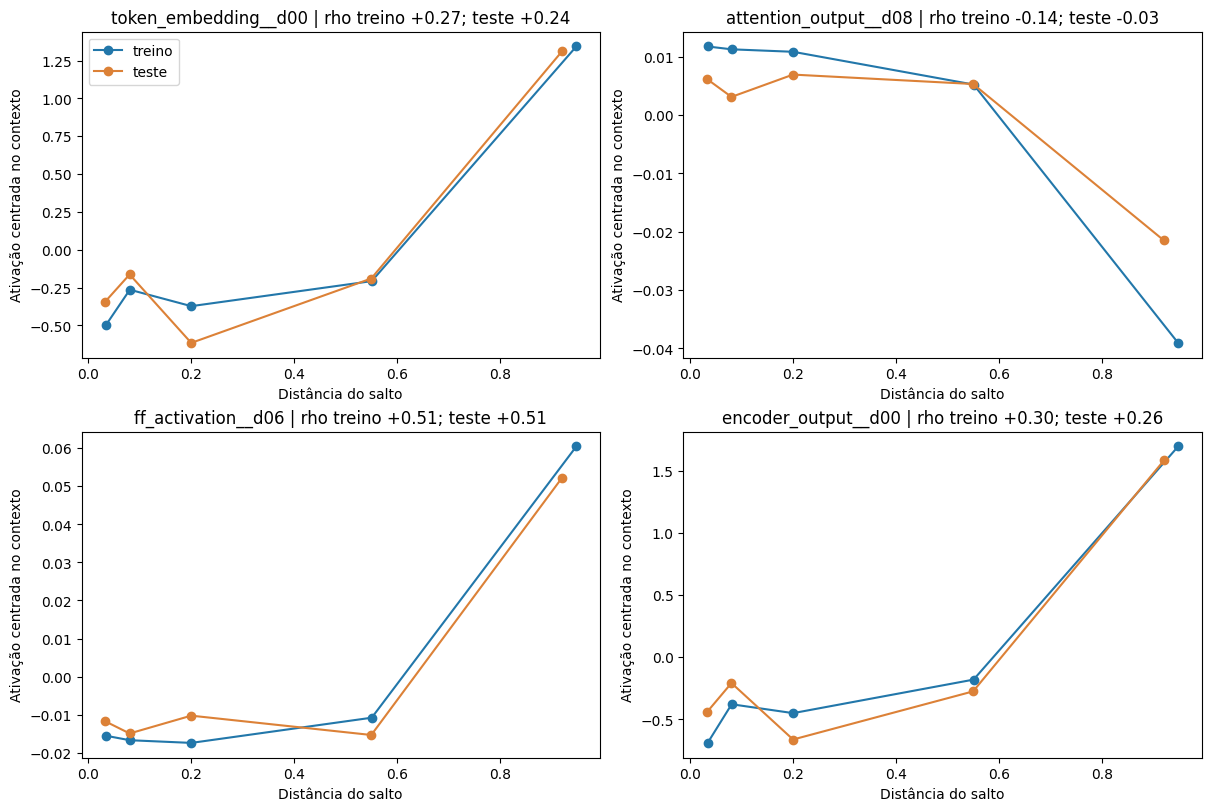

,representacao,R2_teste_distancia_centrada
0,token_embedding,0.264
1,attention_output,0.052
2,ff_activation,0.282
3,encoder_output,0.219


In [6]:
fig,axes=plt.subplots(2,2,figsize=(12,8),constrained_layout=True)
for ax,feature in zip(axes.flat,selected):
    for name,color in [('treino','#2277aa'),('teste','#dc8137')]:
        part=synthetic[synthetic.split==name].copy()
        part['centered_activation']=part[feature]-part.groupby('anchor_id')[feature].transform('mean')
        group=part.groupby('category').mean(numeric_only=True).reindex(order[1:])
        ax.plot(group.centroid_distance,group.centered_activation,marker='o',color=color,label=name)
    ax.set(xlabel='Distância do salto',ylabel='Ativação centrada no contexto',
           title=f'{feature} | rho treino {comparison.loc[feature,"treino"]:+.2f}; teste {comparison.loc[feature,"teste"]:+.2f}')
axes.flat[0].legend()
fig.savefig(root/'imgs/hardpos_saltos_dimensoes.png',dpi=150,bbox_inches='tight')
display(fig)
plt.close(fig)

# Decodificação de distância: remove a média de cada contexto para exigir comparação entre variantes.
train_mask=(synthetic.split=='treino').to_numpy()
test_mask=~train_mask
y=synthetic.centroid_distance.to_numpy(float)
y_center=y-synthetic.groupby('anchor_id').centroid_distance.transform('mean').to_numpy(float)
rows=[]
for stage in ['token_embedding','attention_output','ff_activation','encoder_output']:
    cols=[c for c in feature_cols if c.startswith(stage+'__')]
    x=synthetic[cols].to_numpy(float)
    x_center=x-synthetic.groupby('anchor_id')[cols].transform('mean').to_numpy(float)
    reg=make_pipeline(StandardScaler(),Ridge(alpha=100.0))
    reg.fit(x_center[train_mask],y_center[train_mask])
    pred=reg.predict(x_center[test_mask])
    rows.append((stage,r2_score(y_center[test_mask],pred)))
decoding=pd.DataFrame(rows,columns=['representacao','R2_teste_distancia_centrada'])
display(decoding.round(3))

## Controle do PS final

Uma dimensão pode parecer sensível à distância simplesmente por reconhecer o PS de destino. Por isso removemos, alternadamente, a média de cada contexto de origem e a média de cada PS candidato. Em seguida correlacionamos os resíduos com a distância. O mesmo procedimento aplicado ao embedding do último PS deve produzir correlação próxima de zero. Muitos destinos aparecem poucas vezes, então este controle é descritivo e pode também remover parte de um efeito real.

,split,feature,r_contexto,r_contexto_e_destino
0,teste,token_embedding__d00,0.300,0.000
1,teste,attention_output__d08,-0.093,0.023
2,teste,ff_activation__d06,0.380,0.015
3,teste,encoder_output__d00,0.336,0.025
4,treino,token_embedding__d00,0.313,0.000
5,treino,attention_output__d08,-0.192,-0.014
6,treino,ff_activation__d06,0.424,0.019
7,treino,encoder_output__d00,0.376,0.015


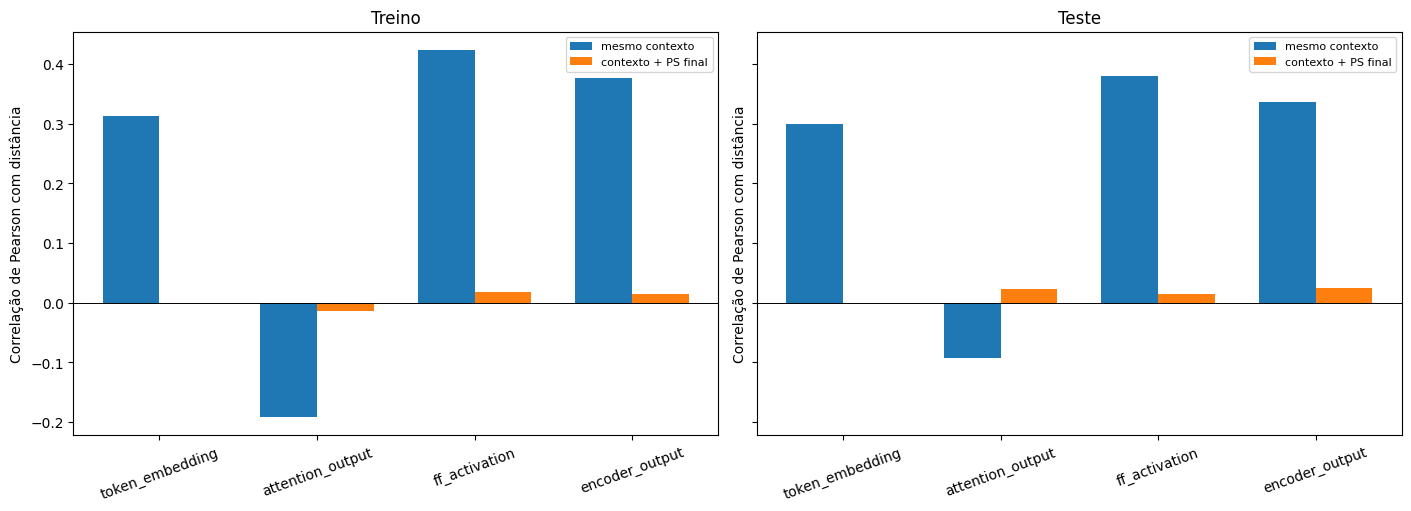

Fração de ativação da unidade feedforward selecionada: ff_activation__d06


split,teste,treino
category,,
perto,0.055,0.059
medio,0.051,0.055
grande,0.059,0.070
fora_envelope,0.043,0.074
mais_distante,0.441,0.516


In [7]:
def residualize_groups(values, group_a, group_b, iterations=100):
    r=np.asarray(values,dtype=float).copy()
    for _ in range(iterations):
        for group in (group_a,group_b):
            counts=np.bincount(group)
            means=np.bincount(group,weights=r)/np.maximum(counts,1)
            r-=means[group]
    return r

control_rows=[]
for split_name,part in synthetic.groupby('split'):
    source,_=pd.factorize(part.anchor_id)
    destination,_=pd.factorize(part.candidate_ps_id)
    dist=part.centroid_distance.to_numpy(float)
    source_dist=dist-pd.Series(dist).groupby(source).transform('mean').to_numpy()
    controlled_dist=residualize_groups(dist,source,destination)
    for feature in selected:
        a=part[feature].to_numpy(float)
        source_a=a-pd.Series(a).groupby(source).transform('mean').to_numpy()
        controlled_a=residualize_groups(a,source,destination)
        r_source=float(np.corrcoef(source_a,source_dist)[0,1]) if source_a.std()>1e-9 else np.nan
        r_both=float(np.corrcoef(controlled_a,controlled_dist)[0,1]) if controlled_a.std()>1e-9 else np.nan
        control_rows.append((split_name,feature,r_source,r_both))
controls=pd.DataFrame(control_rows,columns=['split','feature','r_contexto','r_contexto_e_destino'])
controls.to_csv(notebook_csv_path('HardPos_saltos_ps', 'HardPos_saltos_ps_controles.csv'),index=False)
display(controls.round(3))

fig,axes=plt.subplots(1,2,figsize=(14,5),sharey=True,constrained_layout=True)
for ax,split_name in zip(axes,('treino','teste')):
    part=controls[controls.split==split_name].set_index('feature').loc[selected]
    x=np.arange(len(selected))
    ax.bar(x-.18,part.r_contexto,width=.36,label='mesmo contexto')
    ax.bar(x+.18,part.r_contexto_e_destino,width=.36,label='contexto + PS final')
    ax.set_xticks(x,[s.split('__')[0] for s in selected],rotation=20)
    ax.axhline(0,color='black',lw=.7)
    ax.set_title(split_name.capitalize())
    ax.set_ylabel('Correlação de Pearson com distância')
    ax.legend(fontsize=8)
fig.savefig(root/'imgs/hardpos_saltos_controle_destino.png',dpi=150,bbox_inches='tight')
display(fig)
plt.close(fig)

unit=selected[2]
activation_rate=(synthetic.assign(active=synthetic[unit]>0)
                 .groupby(['split','category']).active.mean().unstack('split').reindex(order[1:]))
print('Fração de ativação da unidade feedforward selecionada:',unit)
display(activation_rate.round(3))

## Interpretação

A correlação com a distância sintética informa se uma dimensão muda sistematicamente ao trocar o último PS. Isso ainda não identifica uma speed cell: o modelo pode estar reagindo ao PS final ou à surpresa de uma transição inédita. O controle de PS final permite verificar se o padrão de distância permanece depois de descontar o destino. Uma evidência mais forte exigiria resposta consistente à velocidade real em trajetórias com intervalos temporais conhecidos e controle do PS de destino. O decodificador de distância compara as representações internas ao embedding do PS final, que não vê o PS anterior.